In [2]:
import os
import glob
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from tqdm import tqdm
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from concurrent.futures.process import BrokenProcessPool
import glob
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import re

<span style="color:red"> TODO: </span> run this for all raw_profiles in: "data_dir="/Volumes/USB/raw_profiles"

### Load phased data

In [3]:
def load_data(file_path: str):
    
    # columns 
    feature_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    time_col_candidates = ['timestamp_dst', 'timestamp', 'timestamp_utc']
        
    # read Parquet data
    parquet_file = pq.ParquetFile(file_path)
    file_cols = parquet_file.schema.names
    cols_to_load = []
    rename_map = {}
    for base_feat in feature_cols:
        matched_col = next((c for c in file_cols if c.startswith(base_feat)), None)
        if matched_col:
            cols_to_load.append(matched_col)
            rename_map[matched_col] = base_feat
    
    time_col_name = next((c for c in file_cols if c.lower() in time_col_candidates), None)
    if time_col_name and time_col_name not in cols_to_load:
        cols_to_load.append(time_col_name)
        
    if not cols_to_load:
        return 0, 0, 0, 0, 0
        
    df = pq.read_table(file_path, columns=cols_to_load).to_pandas()
    df = df.rename(columns=rename_map)

    # time index prep
    time_values = df[time_col_name] if time_col_name in df.columns else df.index
    df.index = pd.to_datetime(time_values, errors='coerce', utc=True)
    df = df[~df.index.isna() & ~df.index.duplicated(keep='last')].sort_index()
    if df.empty:
        return 0, 0, 0, 0, 0

    return df

data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
df = load_data(os.path.join(data_dir, "sm_17.parquet"))
print(df.head())

                           active_power_p14_l1  active_power_p14_l2  \
timestamp_dst                                                         
2023-09-04 08:45:00+00:00                 <NA>                 <NA>   
2023-09-04 09:00:00+00:00                 <NA>                 <NA>   
2023-09-04 09:15:00+00:00                 <NA>                 <NA>   
2023-09-04 09:30:00+00:00                 <NA>                 <NA>   
2023-09-04 09:45:00+00:00                 <NA>                 <NA>   

                           active_power_p14_l3  
timestamp_dst                                   
2023-09-04 08:45:00+00:00                 <NA>  
2023-09-04 09:00:00+00:00                 <NA>  
2023-09-04 09:15:00+00:00                 <NA>  
2023-09-04 09:30:00+00:00                 <NA>  
2023-09-04 09:45:00+00:00                 <NA>  


### 1) How many meters have 1, 2, or 3 phased HP? 

use hp conditioner 

In [ ]:
from conditioner import HeatpumpConditioner

def count_active_phases_in_meter(df: pd.DataFrame) -> int:
    phase_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    active_count = 0
    for col in phase_cols:
        if col in df.columns and df[col].notna().any() and (df[col].fillna(0.0) != 0.0).any():
            active_count += 1
    return active_count

def _to_binary_hp(series: pd.Series) -> pd.Series:
    lowered = series.astype(str).str.strip().str.lower()
    return lowered.isin({'true', '1', 'yes', 'y', 't'}).astype(float)


def build_hp_lookup_from_label_file(hp_label_path: str) -> dict[int, float]:

    label_df = pd.read_csv(hp_label_path)
    lower_map = {c.lower(): c for c in label_df.columns}
    meter_col = None
    hp_col = None

    for candidate in ['meter_number', 'meter_id', 'meter', 'id']:
        if candidate in lower_map:
            meter_col = lower_map[candidate]
            break

    for candidate in ['has_heat_pump', 'predicted_hp', 'heat_pump', 'is_hp', 'hp']:
        if candidate in lower_map:
            hp_col = lower_map[candidate]
            break

    if hp_col is None:
        raise ValueError('Could not find HP label column in hp_label_path file.')

    # If no explicit meter column exists, parse trailing digits from first/unnamed column (e.g. l1_100025)
    if meter_col is None:
        unnamed_cols = [c for c in label_df.columns if str(c).lower().startswith('unnamed')]
        source_col = unnamed_cols[0] if unnamed_cols else label_df.columns[0]
        meter_vals = pd.to_numeric(label_df[source_col].astype(str).str.extract(r'(\d+)$')[0], errors='coerce')
    else:
        meter_vals = pd.to_numeric(label_df[meter_col], errors='coerce')

    hp_vals = _to_binary_hp(label_df[hp_col])
    tmp = pd.DataFrame({'meter_id': meter_vals, 'hp': hp_vals}).dropna(subset=['meter_id'])
    tmp['meter_id'] = tmp['meter_id'].astype(int)

    # Aggregate by meter (if any phase says True => meter is HP)
    grouped = tmp.groupby('meter_id', as_index=False)['hp'].max()
    return {int(r['meter_id']): float(r['hp']) for _, r in grouped.iterrows()}


def count_hp_meters_by_phase(
    data_dir: str,
    hp_label_path: str,
):

    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))

    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    # Try HeatpumpConditioner first; if schema mismatches, fallback to local parser
    hp_lookup = None
    try:
        hp_conditioner = HeatpumpConditioner(topology_path=hp_label_path)
    except Exception:
        hp_conditioner = None
        hp_lookup = build_hp_lookup_from_label_file(hp_label_path)

    phase_counts = {1: 0, 2: 0, 3: 0}
    analyzed_hp_meters = 0
    skipped_non_hp = 0
    skipped_invalid = 0

    for file_path in tqdm(parquet_files, desc='Counting phased HP meters', unit='file'):
        file_name = os.path.basename(file_path)
        try:
            meter_id = int(file_name.split('_')[1].split('.')[0])
        except Exception:
            skipped_invalid += 1
            continue

        try:
            if hp_conditioner is not None:
                hp_flag = hp_conditioner.get_conditions(
                    x=None,
                    meter_id=np.array([meter_id]),
                    timestamps=None,
                ).squeeze().item()
            else:
                hp_flag = hp_lookup.get(meter_id, 0.0)

        except Exception:
            # If conditioner fails due schema mismatch, fallback to parsed lookup
            if hp_lookup is None:
                hp_lookup = build_hp_lookup_from_label_file(hp_label_path)
            hp_flag = hp_lookup.get(meter_id, 0.0)

        if hp_flag < 0.5:
            skipped_non_hp += 1
            continue

        df = load_data(file_path)

        if isinstance(df, int) or df is None or df.empty:
            skipped_invalid += 1
            continue

        n_active = count_active_phases_in_meter(df)
        if n_active in phase_counts:
            phase_counts[n_active] += 1
            analyzed_hp_meters += 1
        else:
            skipped_invalid += 1

    summary_df = pd.DataFrame({
        'active_phases': [1, 2, 3],
        'hp_meter_count': [phase_counts[1], phase_counts[2], phase_counts[3]],
    })

    total_hp = int(summary_df['hp_meter_count'].sum())
    summary_df['pct_of_hp_meters'] = (
        summary_df['hp_meter_count'] / total_hp * 100.0 if total_hp > 0 else 0.0
    )

    print('\n' + '=' * 70)
    print('PHASED HEATPUMP METER SUMMARY')
    print('=' * 70)
    print(f'Total parquet files: {len(parquet_files)}')
    print(f'HP meters analyzed: {analyzed_hp_meters}')
    print(f'Non-HP meters skipped: {skipped_non_hp}')
    print(f'Invalid/empty/skipped files: {skipped_invalid}')
    print('=' * 70)
    display(summary_df)
    return summary_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
hp_label_path = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/label_propagation_predictions.csv'
data_dir = '/Volumes/USB/raw_profiles'
hp_phase_summary = count_hp_meters_by_phase(
    data_dir=data_dir,
    hp_label_path=hp_label_path,
)

Counting phased HP meters: 100%|██████████| 61557/61557 [14:40<00:00, 69.91file/s]  


PHASED HEATPUMP METER SUMMARY
Total parquet files: 61557
HP meters analyzed: 33452
Non-HP meters skipped: 28105
Invalid/empty/skipped files: 0


,active_phases,hp_meter_count,pct_of_hp_meters
0,1,158,0.472319
1,2,1019,3.046156
2,3,32275,96.481526


Counting phased HP meters: 100%|██████████| 61557/61557 [14:40<00:00, 69.91file/s]  

======================================================================

PHASED HEATPUMP METER SUMMARY

======================================================================

Total parquet files: 61557

HP meters analyzed: 33452

Non-HP meters skipped: 28105

Invalid/empty/skipped files: 0

======================================================================

active_phases	hp_meter_count	pct_of_hp_meters

0	1	158	0.472319

1	2	1019	3.046156

2	3	32275	96.481526

### 2) How many meters have 1, 2, or 3 active phases?

In [21]:
def count_active_phases(df):
    phase_cols = ['active_power_p14_l1', 'active_power_p14_l2', 'active_power_p14_l3']
    
    active_count = 0
    for col in phase_cols:
        if col in df.columns:
            # active if at least one valid non-zero value exists
            if df[col].notna().any() and (df[col].fillna(0) != 0).any():
                active_count += 1
                
    return active_count


# data_dir = "/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles"
data_dir = "/Volumes/USB/raw_profiles"

phase_counts = {1: 0, 2: 0, 3: 0}
total_meters = 0

for file in os.listdir(data_dir):
    if not file.endswith(".parquet"):
        continue
        
    df = load_data(os.path.join(data_dir, file))
    
    if isinstance(df, int) or df.empty:
        continue
    
    n_active = count_active_phases(df)
    
    if n_active in phase_counts:
        phase_counts[n_active] += 1
    
    total_meters += 1

print("Total meters:", total_meters)

for k in [1, 2, 3]:
    count = phase_counts[k]
    pct = (count / total_meters) * 100 if total_meters > 0 else 0
    print(f"{k} phase(s): {count} meters ({pct:.2f}%)")

Total meters: 61557
1 phase(s): 1046 meters (1.70%)
2 phase(s): 2899 meters (4.71%)
3 phase(s): 57242 meters (92.99%)


### 3) How many meters have PVs? 

- use topology data

In [22]:

def _to_binary_flag(series: pd.Series) -> pd.Series:
    lowered = series.astype(str).str.strip().str.lower()
    return lowered.isin({'true', '1', 'yes', 'y', 't'}).astype(int)

def count_pv_meters(topology_dir: str, data_dir: str | None = None):

    topology_path = os.path.join(topology_dir, 'MeterAndCabinet.csv')

    if not os.path.exists(topology_path):
        print(f'Missing topology file: {topology_path}')
        return pd.DataFrame()

    topo = pd.read_csv(topology_path)
    required = {'meter_number', 'has_solar_panel'}
    if not required.issubset(set(topo.columns)):
        print(f'Topology file must contain columns: {sorted(required)}')
        return pd.DataFrame()

    topo = topo[['meter_number', 'has_solar_panel']].copy()
    topo['meter_number'] = pd.to_numeric(topo['meter_number'], errors='coerce')
    topo = topo.dropna(subset=['meter_number'])
    topo['meter_number'] = topo['meter_number'].astype(int)
    topo['has_solar_panel_bin'] = _to_binary_flag(topo['has_solar_panel'])

    # Aggregate per meter in case of duplicates: any True => PV meter
    meter_pv = topo.groupby('meter_number', as_index=False)['has_solar_panel_bin'].max()
    total_topology_meters = int(len(meter_pv))
    pv_topology = int(meter_pv['has_solar_panel_bin'].sum())
    no_pv_topology = total_topology_meters - pv_topology

    print('\n' + '=' * 70)
    print('PV METER SUMMARY (TOPOLOGY)')
    print('=' * 70)
    print(f'Total meters in topology: {total_topology_meters:,}')
    print(f'Meters with PV: {pv_topology:,}')
    print(f'Meters without PV: {no_pv_topology:,}')
    print(f'PV share: {(pv_topology / total_topology_meters * 100.0) if total_topology_meters > 0 else 0.0:.2f}%')

    # Optional: overlap with parquet dataset meters

    if data_dir is not None:

        parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
        dataset_ids = []
        for fp in parquet_files:
            name = os.path.basename(fp)
            m = re.search(r'sm_(\d+)\.parquet$', name)
            if m:
                dataset_ids.append(int(m.group(1)))
        dataset_ids = sorted(set(dataset_ids))
        dataset_df = meter_pv[meter_pv['meter_number'].isin(dataset_ids)].copy()
        total_dataset_meters = int(len(dataset_df))
        pv_dataset = int(dataset_df['has_solar_panel_bin'].sum())
        no_pv_dataset = total_dataset_meters - pv_dataset

        print('-' * 70)
        print('PV SUMMARY FOR METERS PRESENT IN PARQUET DATASET')
        print('-' * 70)
        print(f'Meters matched to parquet set: {total_dataset_meters:,}')
        print(f'PV meters in parquet set: {pv_dataset:,}')
        print(f'Non-PV meters in parquet set: {no_pv_dataset:,}')
        print(f'PV share in parquet set: {(pv_dataset / total_dataset_meters * 100.0) if total_dataset_meters > 0 else 0.0:.2f}%')
        print('=' * 70)

        summary_df = pd.DataFrame([
            {'scope': 'topology_all', 'total_meters': total_topology_meters, 'pv_meters': pv_topology, 'non_pv_meters': no_pv_topology},
            {'scope': 'parquet_overlap', 'total_meters': total_dataset_meters, 'pv_meters': pv_dataset, 'non_pv_meters': no_pv_dataset},
        ])
    else:
        print('=' * 70)
        summary_df = pd.DataFrame([
            {'scope': 'topology_all', 'total_meters': total_topology_meters, 'pv_meters': pv_topology, 'non_pv_meters': no_pv_topology},
        ])

    summary_df['pv_pct'] = summary_df.apply(
        lambda r: (r['pv_meters'] / r['total_meters'] * 100.0) if r['total_meters'] > 0 else 0.0,
        axis=1,
    )
    display(summary_df)
    return summary_df


pv_data = '/Volumes/USB/topology/cleaned_and_corrected'
# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
pv_summary = count_pv_meters(topology_dir=pv_data, data_dir=data_dir)


PV METER SUMMARY (TOPOLOGY)
Total meters in topology: 62,312
Meters with PV: 3,771
Meters without PV: 58,541
PV share: 6.05%
----------------------------------------------------------------------
PV SUMMARY FOR METERS PRESENT IN PARQUET DATASET
----------------------------------------------------------------------
Meters matched to parquet set: 61,557
PV meters in parquet set: 3,740
Non-PV meters in parquet set: 57,817
PV share in parquet set: 6.08%


,scope,total_meters,pv_meters,non_pv_meters,pv_pct
0,topology_all,62312,3771,58541,6.051804
1,parquet_overlap,61557,3740,57817,6.075670


### 4) How many windows are flagged as holiday? 

window = 24h 
use the holiday conditioner

In [4]:
from conditioner import HolidayConditioner

def count_holiday_flagged_windows(
    data_dir: str,
    holiday_path: str = 'data/holidays/denmark_holidays.json',
    window_hours: int = 24,
    stride_steps: int = 1,
    verbose: bool = False,
):
    holiday_conditioner = HolidayConditioner(holiday_path=holiday_path)
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    rows = []
    for file_path in tqdm(parquet_files, desc='Counting holiday-flagged windows', unit='file'):
        try:
            df = load_data(file_path)

            if isinstance(df, int) or df is None or df.empty:
                continue

            if len(df.index) < 2:
                continue

            # Infer base time step from median delta between timestamps
            deltas = pd.Series(df.index).diff().dropna().dt.total_seconds().to_numpy()

            if deltas.size == 0:
                continue
            step_seconds = int(np.median(deltas))
            if step_seconds <= 0:
                continue

            window_len_steps = max(1, int(round((window_hours * 3600) / step_seconds)))
            if len(df) < window_len_steps:
                rows.append({
                    'file': os.path.basename(file_path),
                    'total_windows': 0,
                    'holiday_windows': 0,
                    'holiday_pct': 0.0,
                    'step_seconds': step_seconds,
                    'window_len_steps': window_len_steps,
                })
                continue

            starts = np.arange(0, len(df) - window_len_steps + 1, stride_steps, dtype=int)
            start_timestamps = [df.index[s] for s in starts]

            # Matches training logic: holiday flag is computed from window START timestamp
            flags = holiday_conditioner.get_conditions(
                x=None,
                meter_id=None,
                timestamps=start_timestamps,
            ).squeeze(1).cpu().numpy()

            total_windows = int(len(starts))
            holiday_windows = int((flags > 0.5).sum())
            holiday_pct = (holiday_windows / total_windows * 100.0) if total_windows > 0 else 0.0

            rows.append({
                'file': os.path.basename(file_path),
                'total_windows': total_windows,
                'holiday_windows': holiday_windows,
                'holiday_pct': holiday_pct,
                'step_seconds': step_seconds,
                'window_len_steps': window_len_steps,
            })

            if verbose:
                print(f"{os.path.basename(file_path)} -> holiday windows: {holiday_windows}/{total_windows} ({holiday_pct:.2f}%)")
        except Exception as exc:
            if verbose:
                print(f"Failed for {os.path.basename(file_path)}: {exc}")
    summary_df = pd.DataFrame(rows)

    if summary_df.empty:
        print('No valid windows found to summarize.')
        return summary_df
    
    total_windows_all = int(summary_df['total_windows'].sum())
    holiday_windows_all = int(summary_df['holiday_windows'].sum())
    holiday_pct_all = (holiday_windows_all / total_windows_all * 100.0) if total_windows_all > 0 else 0.0
    print('\n' + '=' * 70)
    print('HOLIDAY FLAGGED WINDOWS SUMMARY (24H WINDOWS)')
    print('=' * 70)
    print(f"Files analyzed: {len(summary_df)}")
    print(f"Total windows: {total_windows_all:,}")
    print(f"Holiday-flagged windows: {holiday_windows_all:,}")
    print(f"Holiday-flagged share: {holiday_pct_all:.2f}%")
    print('=' * 70)
    return summary_df.sort_values('holiday_windows', ascending=False).reset_index(drop=True)

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
holiday_windows_summary = count_holiday_flagged_windows(
    data_dir=data_dir,
    holiday_path='/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/denmark_holidays.json',
    window_hours=24,
    stride_steps=1,
    verbose=False,
)
display(holiday_windows_summary.head(10))

Counting holiday-flagged windows: 100%|██████████| 61557/61557 [2:29:11<00:00,  6.88file/s]  



HOLIDAY FLAGGED WINDOWS SUMMARY (24H WINDOWS)
Files analyzed: 61557
Total windows: 1,572,781,350
Holiday-flagged windows: 76,823,136
Holiday-flagged share: 4.88%


,file,total_windows,holiday_windows,holiday_pct,step_seconds,window_len_steps
0,sm_100025.parquet,25550,1248,4.88454,900,96
1,sm_696996.parquet,25550,1248,4.88454,900,96
2,sm_699044.parquet,25550,1248,4.88454,900,96
3,sm_699053.parquet,25550,1248,4.88454,900,96
4,sm_699055.parquet,25550,1248,4.88454,900,96
5,sm_699059.parquet,25550,1248,4.88454,900,96
6,sm_699066.parquet,25550,1248,4.88454,900,96
7,sm_699074.parquet,25550,1248,4.88454,900,96
8,sm_699078.parquet,25550,1248,4.88454,900,96
9,sm_699090.parquet,25550,1248,4.88454,900,96


Counting holiday-flagged windows: 100%|██████████| 61557/61557 [2:29:11<00:00,  6.88file/s]  

======================================================================

HOLIDAY FLAGGED WINDOWS SUMMARY (24H WINDOWS)

======================================================================

Files analyzed: 61557

Total windows: 1,572,781,350

Holiday-flagged windows: 76,823,136

Holiday-flagged share: 4.88%

======================================================================

file	total_windows	holiday_windows	holiday_pct	step_seconds	window_len_steps

0	sm_100025.parquet	25550	1248	4.88454	900	96

1	sm_696996.parquet	25550	1248	4.88454	900	96

2	sm_699044.parquet	25550	1248	4.88454	900	96

3	sm_699053.parquet	25550	1248	4.88454	900	96

4	sm_699055.parquet	25550	1248	4.88454	900	96

5	sm_699059.parquet	25550	1248	4.88454	900	96

6	sm_699066.parquet	25550	1248	4.88454	900	96

7	sm_699074.parquet	25550	1248	4.88454	900	96

8	sm_699078.parquet	25550	1248	4.88454	900	96

9	sm_699090.parquet	25550	1248	4.88454	900	96


### 5) How many meters are categorized as each of the profiles? <span style="color:red"> doesnt make sense before we have the final user_profiler </span>

use the user profiler

In [ ]:
# Calculator: how many meters are categorized into each UserProfiler profile/topic

from conditioner import UserProfiler

def count_meters_per_profile(
    data_dir: str,
    profiler_path: str = 'models/UserProfiles/user_profiles.pkl',
    use_cached_only: bool = True,
):
    profiler = UserProfiler(path=profiler_path, verbose=False)
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame(), pd.DataFrame()

    meter_ids = []
    for file_path in parquet_files:
        name = os.path.basename(file_path)
        match = re.search(r'sm_(\d+)\.parquet$', name)
        if match:
            meter_ids.append(int(match.group(1)))

    meter_ids = sorted(set(meter_ids))
    if not meter_ids:
        print('No meter IDs could be parsed from parquet filenames.')
        return pd.DataFrame(), pd.DataFrame()

    cached_ids = set(int(m) for m in profiler.user_profiles_cache.keys())
    available_ids = [m for m in meter_ids if m in cached_ids]
    missing_ids = [m for m in meter_ids if m not in cached_ids]

    if not available_ids:
        print('No requested meters were found in UserProfiler cache.')
        print('fit/load the profiler first so user_profiles_cache contains these meters.')
        return pd.DataFrame(), pd.DataFrame()

    if (not use_cached_only) and missing_ids:
        # For unseen meters, get_conditions with x=None falls back to uniform profile.
        # Kept optional because that can blur profile distribution.
        extra = profiler.get_conditions(x=None, meter_id=np.array(missing_ids), timestamps=None).numpy()
        for meter_id, vec in zip(missing_ids, extra):
            profiler.user_profiles_cache[meter_id] = vec
        available_ids = sorted(set(available_ids + missing_ids))
        missing_ids = []

    rows = []
    for meter_id in available_ids:
        vec = np.asarray(profiler.user_profiles_cache[meter_id], dtype=float)
        dominant_profile = int(np.argmax(vec) + 1)  # 1..n_topics
        confidence = float(np.max(vec))
        rows.append({
            'meter_id': int(meter_id),
            'dominant_profile': dominant_profile,
            'confidence': confidence,
        })

    meter_profile_df = pd.DataFrame(rows)
    summary = (
        meter_profile_df
        .groupby('dominant_profile', as_index=False)
        .agg(meter_count=('meter_id', 'count'), mean_confidence=('confidence', 'mean'))
        .sort_values('meter_count', ascending=False)
    )
    summary['pct_of_categorized'] = 100.0 * summary['meter_count'] / summary['meter_count'].sum()

    print('\n' + '=' * 70)
    print('USER PROFILER CATEGORY SUMMARY')
    print('=' * 70)
    print(f'Total meters found in directory: {len(meter_ids)}')
    print(f'Meters categorized (in profiler cache): {len(available_ids)}')
    print(f'Meters skipped (not in profiler cache): {len(missing_ids)}')
    print(f'Number of profiles/topics: {profiler.n_topics}')
    print('=' * 70)
    display(summary)
    return summary, meter_profile_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
profiler_path = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/models/UserProfiles/user_profiles.pkl'
# data_dir = '/Volumes/USB/raw_profiles'
profile_summary, meter_profile_assignments = count_meters_per_profile(
    data_dir=data_dir,
    profiler_path=profiler_path,
    use_cached_only=True,
)

display(meter_profile_assignments.head(10))


USER PROFILER CATEGORY SUMMARY
Total meters found in directory: 6
Meters categorized (in profiler cache): 6
Meters skipped (not in profiler cache): 0
Number of profiles/topics: 20


,dominant_profile,meter_count,mean_confidence,pct_of_categorized
1,10,3,0.994232,50.000000
0,5,1,0.981441,16.666667
2,11,1,0.999049,16.666667
3,19,1,0.999982,16.666667


,meter_id,dominant_profile,confidence
0,17,10,0.999976
1,40,5,0.981441
2,87,11,0.999049
3,116,10,0.999958
4,146,19,0.999982
5,170,10,0.982762


### 6) How many examples of each days are included in the dataset? 

Count and make a histogram of the distribution of days included, i.e., how many Mondays, how many Tuesdays, etc. 

Counting weekday examples: 100%|██████████| 61557/61557 [38:19<00:00, 26.77file/s] 


WEEKDAY DISTRIBUTION SUMMARY
Files analyzed: 61557
Aggregation mode: rows
Total examples counted: 1,578,629,265


,weekday,count,pct
0,Monday,228314913,14.46
1,Tuesday,227514672,14.41
2,Wednesday,224559936,14.22
3,Thursday,224559936,14.22
4,Friday,224559936,14.22
5,Saturday,224559936,14.22
6,Sunday,224559936,14.22


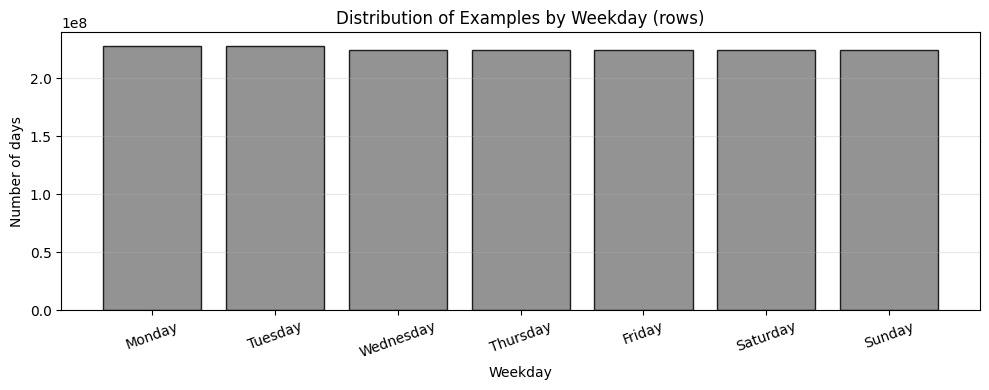

In [5]:
def count_examples_per_weekday(data_dir: str, aggregate: str = 'rows'):
    parquet_files = sorted(glob.glob(os.path.join(data_dir, '*.parquet')))
    if not parquet_files:
        print(f'No parquet files found in {data_dir}')
        return pd.DataFrame()

    weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    weekday_counts = pd.Series(0, index=weekday_order, dtype='int64')

    for file_path in tqdm(parquet_files, desc='Counting weekday examples', unit='file'):
        try:
            df = load_data(file_path)
            if isinstance(df, int) or df is None or df.empty:
                continue

            # Use unique calendar days so each day contributes once per meter
            if aggregate == 'days':
                day_index = pd.DatetimeIndex(df.index.date)
                day_weekdays = pd.to_datetime(pd.Series(day_index.unique())).dt.day_name()
                counts = day_weekdays.value_counts()
            else:
                # Count every timestamp row as an example
                counts = pd.Series(df.index.day_name()).value_counts()
            weekday_counts = weekday_counts.add(counts.reindex(weekday_order, fill_value=0), fill_value=0).astype('int64')
        except Exception:
            continue

    summary_df = pd.DataFrame({
        'weekday': weekday_order,
        'count': weekday_counts.values
    })

    total = int(summary_df['count'].sum())
    summary_df['pct'] = (round(summary_df['count'] / total * 100.0, 2)) if total > 0 else 0.0

    print('\n' + '=' * 70)
    print('WEEKDAY DISTRIBUTION SUMMARY')
    print('=' * 70)
    print(f'Files analyzed: {len(parquet_files)}')
    print(f'Aggregation mode: {aggregate}')
    print(f'Total examples counted: {total:,}')
    print('=' * 70)
    display(summary_df)

    plt.figure(figsize=(10, 4))
    plt.bar(summary_df['weekday'], summary_df['count'], color='gray', edgecolor='black', alpha=0.85)
    plt.title(f'Distribution of Examples by Weekday ({aggregate})')
    plt.xlabel('Weekday')
    plt.ylabel('Number of days')
    plt.xticks(rotation=20)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    return summary_df

# data_dir = '/Users/clarareginekold/Desktop/dtu/THESIS/rasmus-clara-synthetic-data/data/raw_profiles'
data_dir = '/Volumes/USB/raw_profiles'
# aggregate='rows' counts every timestamp row; aggregate='days' counts unique calendar days per meter
weekday_distribution = count_examples_per_weekday(data_dir=data_dir, aggregate='rows')